# Module 1 · The whole document in every prompt

The baseline: send the full Acme 10-Q plus each question to the model, the way a chat app handles an uploaded PDF, and read the `usage` field.

Watch **input tokens stay at the size of the document** on every follow-up. This is Module 1. Every later version is measured against it.

**Setup:** see `README.md` (`pip install -e .`, then `.env` names the model and server). Run with the *Agentic RAG demos* kernel.
The filing is synthetic. Regenerate it with `python data/make_acme_10q.py`.

In [1]:
import os
import time
from pathlib import Path

import litellm
import pandas as pd

from tools.charts import compare, save_runs # bar charts, and the numbers Modules 2 and 4 compare against
from tools.settings import LLM_KWARGS, MODEL, ROOT, price # reads .env: model, server, price

doc = (ROOT / "data" / "acme_10q.txt").read_text() # ROOT: works from demos/
doc_tokens = litellm.token_counter(model=MODEL, text=doc)
print(f"Model: {MODEL}")
print(f"Document: {len(doc):,} characters ≈ {doc_tokens:,} tokens")

Model: gemini/gemini-3.5-flash
Document: 364,256 characters ≈ 100,354 tokens


## One conversation, three follow-ups

Chat APIs are stateless. Every turn resends the system prompt, **the whole document**, and the conversation so far.
`ask()` streams the answer so we can time the first token, then prints what the provider billed.

In [2]:
SYSTEM = "You answer questions about the attached quarterly filing. Be brief and cite the section you used."

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": f"<document name=\"Acme 10-Q\">\n{doc}\n</document>"},
    {"role": "assistant", "content": "I've read the filing. What would you like to know?"},
]
runs = []


def ask(question: str) -> None:
    messages.append({"role": "user", "content": question})
    start = time.perf_counter()
    ttft = None
    chunks = []
    print(f"› {question}\n")
    for chunk in litellm.completion(model=MODEL, messages=messages, stream=True,
                                    stream_options={"include_usage": True}, **LLM_KWARGS):
        chunks.append(chunk)
        delta = chunk.choices[0].delta.content if chunk.choices else None
        if delta:
            ttft = ttft or time.perf_counter() - start
            print(delta, end="", flush=True)
    reply = litellm.stream_chunk_builder(chunks, messages=messages)
    messages.append({"role": "assistant", "content": reply.choices[0].message.content})

    usage = reply.usage
    details = getattr(usage, "prompt_tokens_details", None)
    cached = getattr(details, "cached_tokens", 0) or 0
    cost = price(usage.prompt_tokens, usage.completion_tokens) # list price, or PRICE_AS's for a local model
    runs.append({"question": question, "prompt_tokens": usage.prompt_tokens, "cached_tokens": cached,
                 "completion_tokens": usage.completion_tokens, "ttft_s": round(ttft or 0, 2),
                 "cost_usd": cost})
    print(f"\n\nprompt_tokens={usage.prompt_tokens:,} cached={cached:,} "
          f"completion_tokens={usage.completion_tokens:,} ttft={ttft or 0:.2f}s "
          f"cost={'$%.4f' % cost if cost is not None else 'n/a'}")

In [3]:
ask("What was Q3 revenue?")

› What was Q3 revenue?



In

 the third quarter of 2026, Acme Corp's total revenue was

 **$4,212 million** (or approximately $4.21 billion).

**Citations:**


* **Part I, Item 1. Financial Statements (Unaudited)** – *Condensed Consolidated Statements of Operations*


* **Part I, Item 2. Management's Discussion and Analysis of Financial Condition and Results of Operations**

 – *Third Quarter 2026 Highlights*



prompt_tokens=106,853 cached=0 completion_tokens=102 ttft=2.24s cost=$0.1612


In [4]:
ask("How about Q2?")

› How about Q2?



In

 the second quarter of 2026, Acme Corp's total revenue was **

$3,911 million** (or $3.91 billion).

**Citation:**
* **Part

 II – Appendix A. Second Quarter 2026 Results (As Previously Reported)**



prompt_tokens=106,962 cached=104,796 completion_tokens=62 ttft=1.47s cost=$0.1610


In [5]:
ask("And the margin?")

› And the margin?



The operating

 margins for those quarters were:

* **Q3 2026

 Operating Margin:** **21.0%**
* **Q2 2026 Operating Margin:** **1

9.4%**

**Citations:**
* **Part I, Item 2. Management's Discussion

 and Analysis** – *Third Quarter 2026 Highlights* (for Q3 2026)
* **

Part II – Appendix A. Second Quarter 2026 Results (As Previously Reported)** (for Q2 

2026)



prompt_tokens=107,030 cached=104,905 completion_tokens=123 ttft=1.70s cost=$0.1617


## What we paid

In [6]:
df = pd.DataFrame(runs)
df.loc["total"] = df.sum(numeric_only=True)
df.loc["total", "question"] = ""
df

,question,prompt_tokens,cached_tokens,completion_tokens,ttft_s,cost_usd
0,What was Q3 revenue?,106853,0,102,2.24,0.161197
1,How about Q2?,106962,104796,62,1.47,0.161001
2,And the margin?,107030,104905,123,1.70,0.161652
total,,320845,209701,287,5.41,0.483850


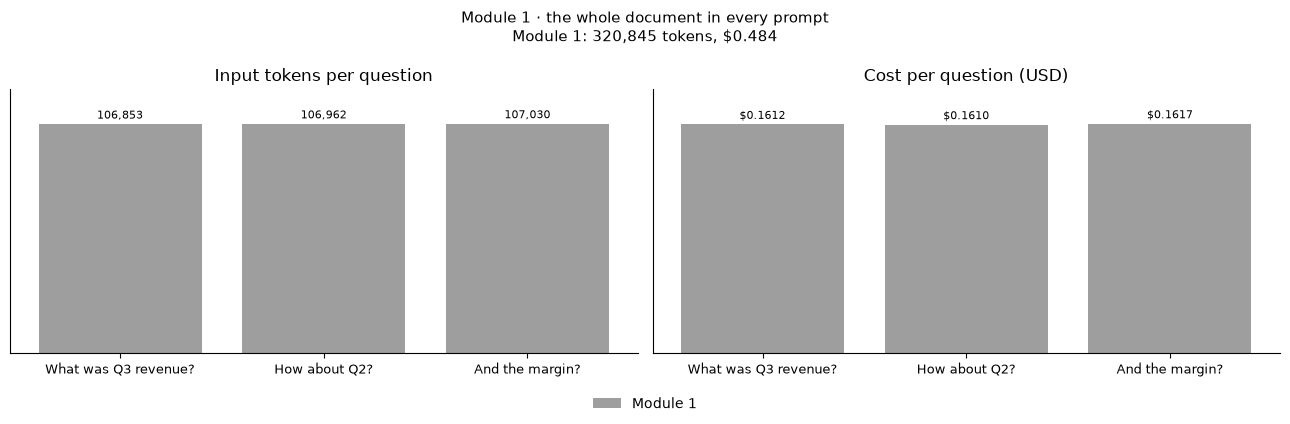

In [7]:
save_runs("module_1", runs) # Modules 2 and 4 chart themselves against these numbers
compare({"Module 1": runs}, "Module 1 · the whole document in every prompt")

## Takeaways

- **Input tokens ≈ document size, every turn.** Three short questions cost ~300K input tokens to read ~100 tokens of relevant facts.
- **Follow-ups make it worse.** The history grows on top of the document, so turn 3 is the largest prompt.
- **Prompt caching softens the bill, not the problem.** OpenAI and Anthropic discount a repeated prefix (`cached_tokens`), but the model still reads the whole filing, the context window still fills, and a new document or user starts cold.
- **Long prompts are slower and less accurate.** Time to first token grows with input, and facts in the middle get missed.

Next, Module 2 sends only the chunks that matter.